In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import Components as comp
import Measurement_functions as mf

laser = comp.Toptica_Laser()



Power =  34.8 mW
Resolution is 4096.0ps
1492117


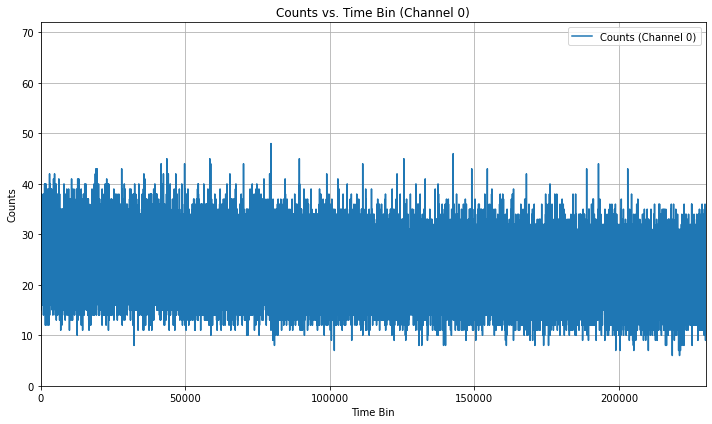

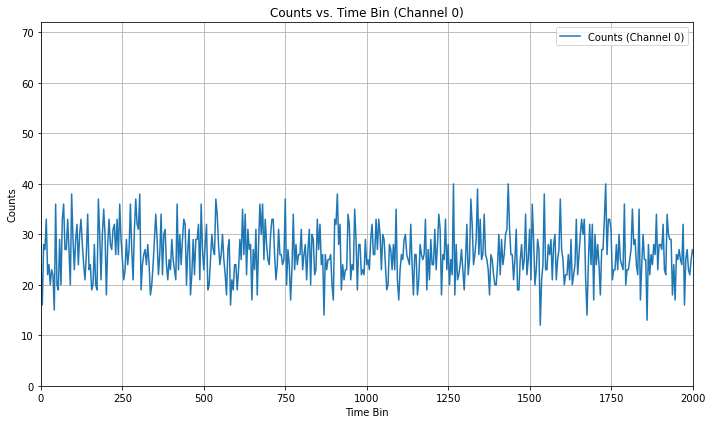

Power =  34.82 mW


KeyboardInterrupt: 

In [3]:
power_list=np.arange(34.8,39.5,0.02)/1000

plot_flag_g2 = False
binning= 12

offset = 0
tacq = 15000
position = 2


for power in power_list:
    print('Power = ', power*1000, 'mW')
    laser.set(power)
    time.sleep(1)
    m_p = 0
    m_v = 0

    scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
    data = scan[0]
    print(sum(data))
    resolution = scan[1]
    mf.save_hh_data(data, resolution, tacq,power*1000,m_v,m_p)
    counts = np.array(data)#/np.mean(data[350:500])
    #print(data[350:520])
    x = np.arange(0,len(counts),1)*4.096
    plt.figure(figsize=(10, 6))
    plt.plot(x,counts, label='Counts (Channel 0)')
    plt.title('Counts vs. Time Bin (Channel 0)')
    plt.xlabel('Time Bin')
    plt.ylabel('Counts')
    plt.xlim(0,230000)
    plt.ylim(0,np.max(counts)*1.5)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(x,counts, label='Counts (Channel 0)')
    plt.title('Counts vs. Time Bin (Channel 0)')
    plt.xlabel('Time Bin')
    plt.ylabel('Counts')
    plt.xlim(0,2000)
    plt.ylim(0,np.max(counts)*1.5)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


laser.set(0)